(52704, 12) | missing: 0 | duplicates: 0
label
Moderate    19022
Good        18439
Poor        15243
Name: count, dtype: int64 



,count,mean,std,min,25%,50%,75%,max
CO,52704.0,508.030472,692.274824,0.0,187.0,268.0,519.0,12876.0
NO2,52704.0,29.616492,23.984409,0.9,11.0,23.3,42.2,218.0
SO2,52704.0,22.387250,34.285823,0.0,0.7,10.5,30.2,497.8
O3,52704.0,53.423668,42.225556,0.0,26.0,48.0,69.0,342.0


Skewness:
 CO     4.940607
NO2    1.456977
SO2    3.664826
O3     1.746438
dtype: float64 

Rows above the 99th percentile: {'CO': 528, 'NO2': 526, 'SO2': 528, 'O3': 521}


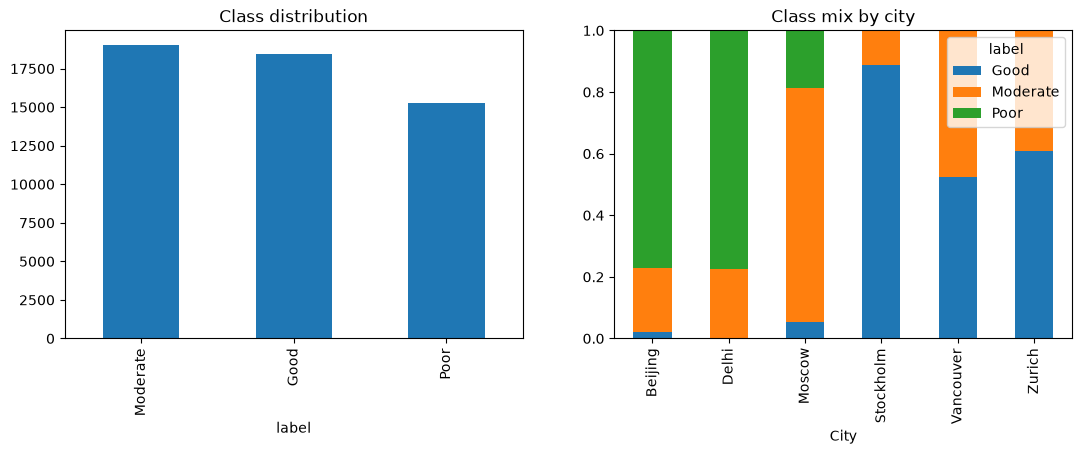

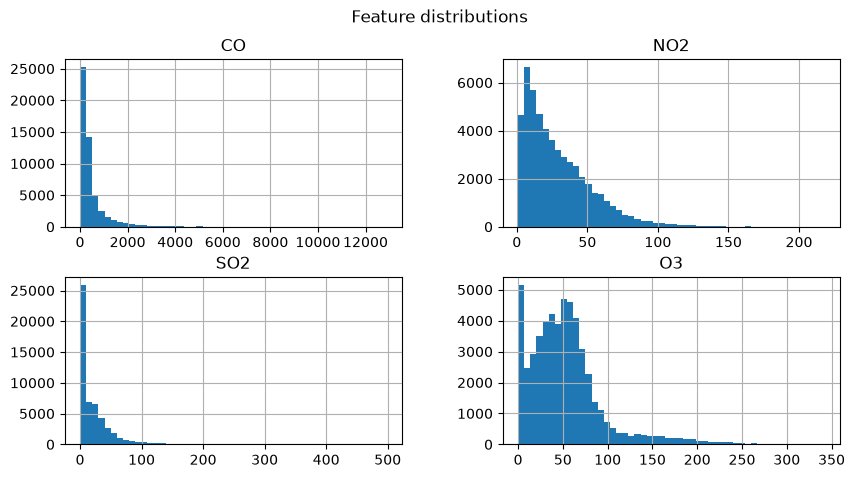

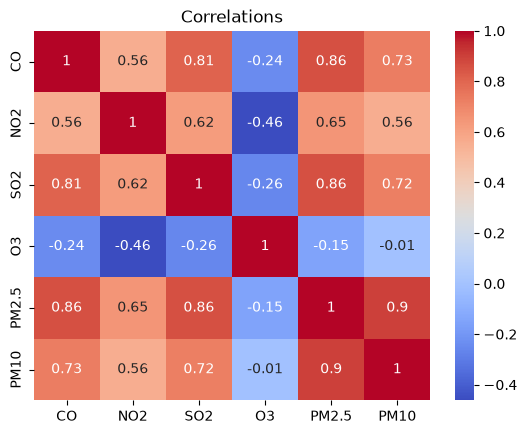

,CO,NO2,SO2,O3
label,,,,
Good,186.496448,12.276517,1.915310,58.900428
Moderate,309.304332,28.361166,15.973236,48.600095
Poor,1144.974283,52.158683,55.155698,52.818015


In [ ]:
import itertools, os, subprocess, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# ---- Settings (change here, nowhere else) ----
CSV_PATH   = "City_Types.csv"
GASES      = ["CO", "NO2", "SO2", "O3"]            # PM2.5 / PM10 excluded: the label is derived from PM2.5
PM25_BINS  = [-1, 9.0, 35.4, 1e9]                  # US EPA 2024 bands; upper categories merged into "Poor"
CLASSES    = ["Good", "Moderate", "Poor"]          # LabelEncoder order: Good=0, Moderate=1, Poor=2
DEPTHS     = [3, 4, 5, 6, 8]                       # candidate tree depths
SEED       = 42



def load_data(path=CSV_PATH):
    """Load the CSV, add the air-quality label, hour and month. Returns (df, y)."""
    df = pd.read_csv(path)
    df["label"] = pd.cut(df["PM2.5"], bins=PM25_BINS, labels=CLASSES)
    df["Date"] = pd.to_datetime(df["Date"])
    df["hour"] = df["Date"].dt.hour
    df["month"] = df["Date"].dt.month
    y = LabelEncoder().fit_transform(df["label"].astype(str))
    return df, y


def tree(depth):
    return DecisionTreeClassifier(max_depth=depth, random_state=SEED)


def loco_predict(model, X, y, cities):
    """Leave-one-city-out. Returns predictions for every row (pooled across held-out cities)."""
    preds = np.empty_like(y)
    for city in cities.unique():
        te = (cities == city).values
        preds[te] = clone(model).fit(X[~te], y[~te]).predict(X[te])
    return preds


def scores(y_true, y_pred, only_present=False):
    """(accuracy, macro F1). only_present=True ignores classes absent from y_true."""
    labels = np.unique(y_true) if only_present else None
    return (accuracy_score(y_true, y_pred),
            f1_score(y_true, y_pred, labels=labels, average="macro"))


def best_depth(X, y, cities, depths=DEPTHS):
    """Pick the depth with the best pooled LOCO macro F1. Returns (depth, {depth: F1})."""
    f1s = {d: scores(y, loco_predict(tree(d), X, y, cities))[1] for d in depths}
    return max(f1s, key=f1s.get), f1s


def tune_and_test(df, y, feats, test_cities, depths=DEPTHS):
    """Tune depth on the other cities (LOCO), then test once on `test_cities`."""
    test_mask = df["City"].isin(test_cities).values
    dev = df[~test_mask].reset_index(drop=True)
    d, _ = best_depth(dev[feats], y[~test_mask], dev["City"], depths)
    model = tree(d).fit(dev[feats], y[~test_mask])
    pred = model.predict(df.loc[test_mask, feats])
    acc, f1 = scores(y[test_mask], pred, only_present=True)
    return {"depth": d, "nodes": model.tree_.node_count, "acc": acc, "f1": f1}


def tree_to_c(model, feature_names, class_names, func="aq_predict"):
    """Convert a fitted sklearn decision tree to a C function made of nested if/else."""
    t = model.tree_
    args = ", ".join(f"float {n.lower()}" for n in feature_names)
    lines = ["// Auto-generated decision tree. Do not edit by hand.",
             f"// Features (in order): {', '.join(feature_names)}",
             f"// Classes: {', '.join(f'{i}={c}' for i, c in enumerate(class_names))}",
             "#pragma once", "",
             f"static inline int {func}({args}) {{"]

    def rec(node, level):
        pad = "    " * level
        if t.children_left[node] == -1:
            k = int(np.argmax(t.value[node][0]))
            lines.append(f"{pad}return {k};   // {class_names[k]}")
            return
        thr = float(np.float32(t.threshold[node]))          # sklearn compares float32 inputs
        lines.append(f"{pad}if ({feature_names[t.feature[node]].lower()} <= {thr:.9g}f) {{")
        rec(t.children_left[node], level + 1)
        lines.append(f"{pad}}} else {{")
        rec(t.children_right[node], level + 1)
        lines.append(f"{pad}}}")

    rec(0, 1)
    lines.append("}")
    return "\n".join(lines)


def verify_c(df_in, feats, model, header="aq_model.h"):
    """Compile the generated C and compare its predictions with the sklearn model."""
    n = len(feats)
    src = ('#include <stdio.h>\n#include "%s"\nint main(){ float v[%d];\n'
           ' while(1){ for(int i=0;i<%d;i++){ if(scanf("%%f",&v[i])!=1) return 0; }\n'
           '   printf("%%d\\n", aq_predict(%s)); } }\n') % (
           header, n, n, ", ".join(f"v[{i}]" for i in range(n)))
    open("test_aq.c", "w").write(src)
    subprocess.run(["gcc", "-O2", "-o", "test_aq", "test_aq.c"], check=True)
    inp = "\n".join(" ".join(f"{float(np.float32(v)):.9g}" for v in row) for row in df_in[feats].values)
    c_pred = np.array(subprocess.run(["./test_aq"], input=inp, capture_output=True, text=True).stdout.split(), dtype=int)
    return (c_pred == model.predict(df_in[feats])).mean(), len(c_pred)


def show_confusion(y, pred, title):
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=CLASSES).plot(cmap="Blues")
    plt.title(title)
    plt.show()


df, y = load_data()
X = df[GASES]

print(df.shape, "| missing:", df.isnull().sum().sum(), "| duplicates:", df.duplicated().sum())
print(df["label"].value_counts(), "\n")
display(df[GASES].describe().T)
print("Skewness:\n", df[GASES].skew(), "\n")
print("Rows above the 99th percentile:", {f: int((df[f] > df[f].quantile(0.99)).sum()) for f in GASES})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["label"].value_counts().plot(kind="bar", title="Class distribution", ax=axes[0])
pd.crosstab(df["City"], df["label"], normalize="index").plot(
    kind="bar", stacked=True, title="Class mix by city", ax=axes[1])
plt.show()

df[GASES].hist(bins=50, figsize=(10, 5)); plt.suptitle("Feature distributions"); plt.show()
sns.heatmap(df[GASES + ["PM2.5", "PM10"]].corr(), annot=True, cmap="coolwarm"); plt.title("Correlations"); plt.show()
display(df.groupby("label", observed=True)[GASES].mean())

models = {
    "Decision Tree (depth 8)": tree(8),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
    "Logistic Regression": make_pipeline(FunctionTransformer(np.log1p), StandardScaler(),
                                         LogisticRegression(max_iter=1000)),
}

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
rows = []
for name, model in models.items():
    rows.append([name, "Random split", *scores(y_te, clone(model).fit(X_tr, y_tr).predict(X_te))])
    rows.append([name, "LOCO (pooled)", *scores(y, loco_predict(model, X, y, df["City"]))])

display(pd.DataFrame(rows, columns=["Model", "Evaluation", "Accuracy", "Macro F1"]).round(3))

rows = []
for d in [2, 3, 4, 5, 6, 8, 10]:
    acc, f1 = scores(y, loco_predict(tree(d), X, y, df["City"]))
    rows.append([d, clone(tree(d)).fit(X, y).tree_.node_count, acc, f1])
sweep = pd.DataFrame(rows, columns=["depth", "nodes", "LOCO accuracy", "LOCO macro F1"]).round(3)
display(sweep)

plt.plot(sweep["depth"], sweep["LOCO macro F1"], marker="o")
plt.xlabel("max_depth"); plt.ylabel("LOCO macro F1"); plt.title("Tree depth vs generalisation"); plt.show()

FEATURE_SETS = {"gases": GASES,
                "gases+hour": GASES + ["hour"],
                "gases+hour+month": GASES + ["hour", "month"]}

# (a) your original single test: Delhi + Zurich
for name, feats in FEATURE_SETS.items():
    print(name, {k: round(v, 3) if isinstance(v, float) else v
                 for k, v in tune_and_test(df, y, feats, ["Delhi", "Zurich"]).items()})

# (b) all 15 pairs of held-out cities (about a minute)
t0 = time.time()
rows = []
for pair in itertools.combinations(df["City"].unique(), 2):
    for name, feats in FEATURE_SETS.items():
        rows.append({"held_out": " + ".join(pair), "features": name, **tune_and_test(df, y, feats, list(pair))})
robust = pd.DataFrame(rows)
print(f"\ndone in {time.time()-t0:.0f}s")

display(robust.groupby("features")[["acc", "f1"]].agg(["mean", "std"]).round(3))
display(robust.pivot(index="held_out", columns="features", values="acc").round(3))

FEATURES = GASES
Xf = df[FEATURES]

DEPTH, f1_by_depth = best_depth(Xf, y, df["City"])
print("LOCO macro F1 by depth:", {d: round(s, 3) for d, s in f1_by_depth.items()}, "-> chosen", DEPTH)

# Honest performance estimate (pooled LOCO predictions at the chosen depth)
pred = loco_predict(tree(DEPTH), Xf, y, df["City"])
print(classification_report(y, pred, target_names=CLASSES))
show_confusion(y, pred, f"Decision tree (depth {DEPTH}), leave-one-city-out, pooled")

display(pd.Series({c: accuracy_score(y[(df["City"] == c).values], pred[(df["City"] == c).values])
                   for c in df["City"].unique()}).round(3).to_frame("LOCO accuracy"))

# Deployment model: trained on all cities
final = tree(DEPTH).fit(Xf, y)
print("Nodes:", final.tree_.node_count, "| Leaves:", final.get_n_leaves())
pd.Series(final.feature_importances_, index=FEATURES).sort_values().plot(kind="barh", title="Feature importance")
plt.show()

c_code = tree_to_c(final, FEATURES, CLASSES)
with open("aq_model.h", "w") as fh:
    fh.write(c_code)
print(c_code[:900], "\n...")
print("Lines of C:", c_code.count("\n") + 1, "| File size:", os.path.getsize("aq_model.h"), "bytes")

try:
    match, n = verify_c(df, FEATURES, final)
    print(f"C vs Python agreement on {n} rows: {match*100:.3f}%")
except Exception as e:
    print("Skipped C verification:", e)